# Comparing Different Search Strategies: Maze

<Figure size 640x480 with 0 Axes>

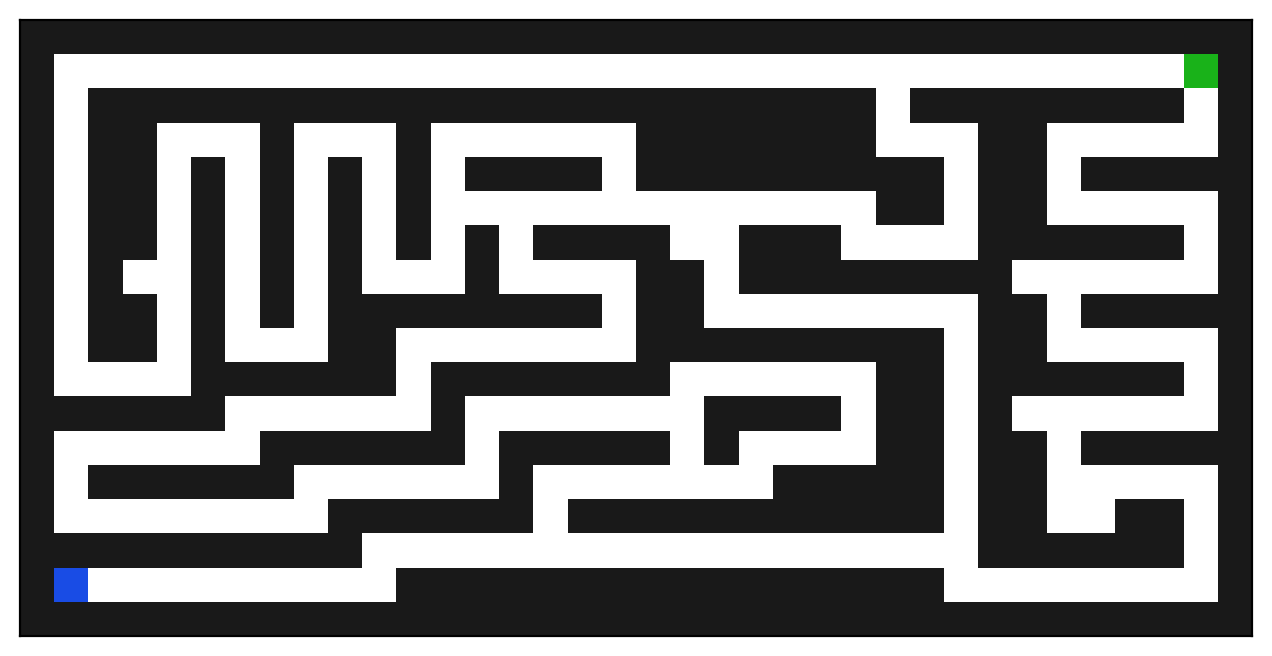

In [12]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np

#f = open("small_maze.txt", "r")
f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
#f = open("L_maze.txt", "r")
import importlib
import maze_helper as mh
import tree_search_solution as ts
importlib.reload(mh)
importlib.reload(ts)
maze_str = f.read()
maze = parse_maze(maze_str)

show_maze(maze)

My implementation follows the pseudo code from the slides/textbook.

In [13]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts


# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)

## Experiments - Uninformed Search

### BFS

In [14]:
%time result = ts.best_first_search(maze, strategy = "BFS", animation = True)
ts.animate_maze(result)

CPU times: user 774 μs, sys: 36 μs, total: 810 μs
Wall time: 775 μs


### DFS 

This implementation does not use a reached data structure and has space complexity $O(bm)$ instead of $O(b^m)$ when we reuse the tree search algorithm from BFS!

We need to check for all cycles. If we do not break all cycles correctly, then we can end up in an infinite loop.

In [23]:
ts.set_order("NESW")

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True, animation = True)
ts.animate_maze(result)

CPU times: user 3.86 ms, sys: 64 μs, total: 3.93 ms
Wall time: 3.91 ms


Note on the visualization: I use gray for areas that the algorithm has explored, but DFS has already removed it from memory so they are shown white.

The exploration order (order used in the expand function) is very important for DFS! DFS uses LIFO so the directions come from the stack in reverse order.

I set the exploration order so that South will be explored before West.

In [24]:
ts.set_order("ENWS")

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True, animation = True)
ts.animate_maze(result)

CPU times: user 4.02 ms, sys: 851 μs, total: 4.87 ms
Wall time: 4.03 ms


The best exploration order depends on the Maze, so we probably should rather use random exploration. Here the order is randomized in at each step. It will produce sometimes give good and sometimes bad solutions and can be used with multi[ple restarts.

In [28]:
ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True, animation = True)
ts.animate_maze(result)

CPU times: user 23.8 ms, sys: 1.43 ms, total: 25.2 ms
Wall time: 23.9 ms


## Experiments - Informed Search

### Greedy Best-First Search (GBFS)

Walks towards the goal using the heuristic. It is greedy and not guaranteed to find the optimal solution.

In [24]:
# set the heuristic to Manhattan distance
ts.heuristic = ts.manhattan

In [18]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "GBFS", animation = True)
ts.animate_maze(result)

CPU times: user 550 μs, sys: 343 μs, total: 893 μs
Wall time: 555 μs


### A* Search

Uses an admissible heuristic and is guaranteed to find the optimal solution. It needs to explore a little more compared to GBFS. 

In [19]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", animation = True)
ts.animate_maze(result)

CPU times: user 1.13 ms, sys: 320 μs, total: 1.45 ms
Wall time: 1.16 ms
